# 02 — Data Cleaning & EDA


In [21]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

def show(markdown_text):
    """Render a dynamically-built string as Markdown output, so numeric findings
    are generated by code rather than typed into a static Markdown cell."""
    display(Markdown(markdown_text))


In [22]:
candidate_paths = [
    Path("../data/raw/data_FraudDetection_JAR2020.csv"),
    Path("data/raw/data_FraudDetection_JAR2020.csv"),
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not locate data_FraudDetection_JAR2020.csv in either "
        f"{candidate_paths[0]} or {candidate_paths[1]}. "
        "Confirm the file has been placed in data/raw/."
    )

df_raw = pd.read_csv(DATA_PATH, low_memory=False)
df = df_raw.copy()  # working copy; df_raw is never modified anywhere below

RAW_VARS = ["act","ap","at","ceq","che","cogs","csho","dlc","dltis","dltt","dp","ib",
            "invt","ivao","ivst","lct","lt","ni","ppegt","pstk","re","rect","sale","sstk",
            "txp","txt","xint","prcc_f"]
RATIO_VARS = ["dch_wc","ch_rsst","dch_rec","dch_inv","soft_assets","ch_cs","ch_cm",
              "ch_roa","issue","bm","dpi","reoa","EBIT","ch_fcf"]
ID_VARS = ["gvkey", "fyear"]
LABEL_META_VARS = ["p_aaer"]
TARGET = "misstate"

show(f"**Loaded:** `{DATA_PATH}`  \n**Shape:** {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")


**Loaded:** `..\data\raw\data_FraudDetection_JAR2020.csv`  
**Shape:** 146,045 rows x 46 columns

In [23]:
def dataset_snapshot(frame, label):
    return {
        "snapshot": label,
        "rows": len(frame),
        "columns": frame.shape[1],
        "unique_companies": frame["gvkey"].nunique() if "gvkey" in frame else np.nan,
        "year_min": frame["fyear"].min() if "fyear" in frame else np.nan,
        "year_max": frame["fyear"].max() if "fyear" in frame else np.nan,
        "positive_labels": int(frame[TARGET].sum()) if TARGET in frame else np.nan,
        "positive_pct": round(frame[TARGET].mean() * 100, 4) if TARGET in frame else np.nan,
        "missing_cells": int(frame.isna().sum().sum()),
        "duplicate_rows": int(frame.duplicated().sum()),
        "duplicate_gvkey_fyear": int(frame.duplicated(subset=["gvkey", "fyear"]).sum())
        if {"gvkey", "fyear"}.issubset(frame.columns) else np.nan,
    }

baseline_snapshot = dataset_snapshot(df, "BEFORE cleaning")
snapshot_log = [baseline_snapshot]  # later sections append AFTER-cleaning snapshots here
pd.DataFrame(snapshot_log)



,snapshot,rows,columns,unique_companies,year_min,year_max,positive_labels,positive_pct,missing_cells,duplicate_rows,duplicate_gvkey_fyear
0,BEFORE cleaning,146045,46,18444,1990,2014,964,0.660,226179,0,0


In [24]:
ratio_missing_vars = [c for c in RATIO_VARS if df[c].isna().sum() > 0]

missing_target_rows = []
for c in ratio_missing_vars:
    is_missing = df[c].isna()
    missing_target_rows.append({
        "variable": c,
        "missing_count": int(is_missing.sum()),
        "missing_pct": round(is_missing.mean() * 100, 3),
        "positive_label_count_among_missing": int(df.loc[is_missing, TARGET].sum()),
        "negative_label_count_among_missing": int((df.loc[is_missing, TARGET] == 0).sum()),
        "positive_rate_among_missing_pct": round(df.loc[is_missing, TARGET].mean() * 100, 4) if is_missing.sum() > 0 else np.nan,
    })
missing_target_table = pd.DataFrame(missing_target_rows).sort_values("missing_pct", ascending=False)
missing_target_table



,variable,missing_count,missing_pct,positive_label_count_among_missing,negative_label_count_among_missing,positive_rate_among_missing_pct
6,ch_cm,17107,11.714,45,17062,0.263
5,ch_cs,15918,10.899,42,15876,0.264
7,ch_roa,12678,8.681,40,12638,0.316
9,dpi,9228,6.319,18,9210,0.195
12,ch_fcf,5407,3.702,20,5387,0.370
1,ch_rsst,4851,3.322,20,4831,0.412
0,dch_wc,4759,3.259,17,4742,0.357
2,dch_rec,4743,3.248,13,4730,0.274
3,dch_inv,4615,3.160,15,4600,0.325
4,soft_assets,592,0.405,0,592,0.000


In [25]:
overall_positive_rate = df[TARGET].mean() * 100
show(
    f"**Overall positive-label rate (for comparison):** {overall_positive_rate:.4f}%  \n\n"
    "If the positive rate *among missing* rows (rightmost column above) is close to the "
    "overall rate for a given variable, that variable's missingness is not obviously "
    "target-related. A rate that differs substantially would need more scrutiny before "
    "any imputation, since it could mean missingness itself carries information about "
    "the target — which would need to be preserved (e.g. as an explicit missingness "
    "indicator) rather than erased by imputation."
)



**Overall positive-label rate (for comparison):** 0.6601%  

If the positive rate *among missing* rows (rightmost column above) is close to the overall rate for a given variable, that variable's missingness is not obviously target-related. A rate that differs substantially would need more scrutiny before any imputation, since it could mean missingness itself carries information about the target — which would need to be preserved (e.g. as an explicit missingness indicator) rather than erased by imputation.

In [26]:
assert df[TARGET].isna().sum() == 0, "Target has missing values — investigate before proceeding."
assert df["gvkey"].isna().sum() == 0, "gvkey has missing values — investigate before proceeding."
assert df["fyear"].isna().sum() == 0, "fyear has missing values — investigate before proceeding."
show("**Confirmed:** no missing values in `misstate`, `gvkey`, or `fyear` — nothing imputed for these by design, and none are needed.")



**Confirmed:** no missing values in `misstate`, `gvkey`, or `fyear` — nothing imputed for these by design, and none are needed.

In [27]:
negative_rows = []
for c in RAW_VARS + RATIO_VARS:
    s = df[c]
    neg_mask = s < 0
    n_neg = int(neg_mask.sum())
    negative_rows.append({
        "variable": c,
        "negative_count": n_neg,
        "negative_pct": round(n_neg / len(df) * 100, 4),
        "minimum": s.min(),
        "positive_label_rate_among_negative_pct": round(df.loc[neg_mask, TARGET].mean() * 100, 4) if n_neg > 0 else np.nan,
    })
negative_summary = pd.DataFrame(negative_rows).sort_values("negative_count", ascending=False)
negative_summary[negative_summary["negative_count"] > 0]



,variable,negative_count,negative_pct,minimum,positive_label_rate_among_negative_pct
41,ch_fcf,85030,58.222,-2.981,0.786
20,re,74424,50.960,"-143,336.328",0.508
39,reoa,73838,50.558,-89.013,0.512
34,ch_cm,70804,48.481,-17.360,0.726
35,ch_roa,69196,47.380,-1.672,0.737
28,dch_wc,65696,44.983,-1.000,0.623
17,ni,64878,44.423,"-98,696.000",0.482
11,ib,64659,44.273,"-44,574.000",0.479
40,EBIT,57153,39.134,-7.016,0.457
29,ch_rsst,55807,38.212,-2.072,0.520


In [28]:
# Classification is a plausibility judgment based on standard accounting definitions,
# applied to the counts computed above — not a blanket "negative = error" rule.
classification_map = {
    # A. Economically meaningful negative values (raw variables)
    "ni": "A. Economically meaningful — net income is commonly negative in loss-making years.",
    "ib": "A. Economically meaningful — income before extraordinary items is commonly negative in loss-making years.",
    "ceq": "A. Economically meaningful, notable — negative common equity reflects financial distress (accumulated losses exceeding paid-in capital).",
    "re": "A. Economically meaningful — negative retained earnings reflect an accumulated deficit.",
    # B. Potential data-quality / definition issues (raw variables)
    "act": "B. Potential data-quality issue — current assets are not expected to be negative under standard accounting.",
    "che": "B. Potential data-quality issue — cash and short-term investments are not expected to be negative.",
    "invt": "B. Potential data-quality issue — inventory is not expected to be negative.",
    "rect": "B. Potential data-quality issue — receivables are not expected to be negative.",
    "sale": "B. Potential data-quality issue — net sales being negative is not standard (could reflect large returns/allowances or a data artifact).",
    # C. Derived ratios where negative values are plausible
    "dch_wc": "C. Economically/mathematically plausible — a decrease in working-capital accruals.",
    "ch_rsst": "C. Economically/mathematically plausible — a decrease in RSST accruals.",
    "dch_rec": "C. Economically/mathematically plausible — a decrease in receivables year over year.",
    "dch_inv": "C. Economically/mathematically plausible — a decrease in inventory year over year.",
    "ch_cs": "C. Economically/mathematically plausible — a decline in cash sales.",
    "ch_cm": "C. Economically/mathematically plausible — a decline in cash margin.",
    "ch_roa": "C. Economically/mathematically plausible — a decline in return on assets.",
    "ch_fcf": "C. Economically/mathematically plausible — a decline in free cash flow.",
    "reoa": "C. Economically/mathematically plausible — negative retained earnings over assets signals distress, consistent with `re` above.",
    "EBIT": "C. Economically/mathematically plausible — negative operating profitability.",
    "bm": "C. Requires investigation if negative — book-to-market is conventionally positive; a negative value would imply negative book equity, which links back to the ceq/re distress cases above rather than being a separate error.",
    "soft_assets": "C. Requires investigation if negative — a soft-asset proportion is conventionally between 0 and 1.",
    "dpi": "C. Requires investigation if negative — depends on construction; not confidently classified without the authors' exact formula.",
}

classification_rows = []
for c in RAW_VARS + RATIO_VARS:
    n_neg = int((df[c] < 0).sum())
    if n_neg > 0:
        classification_rows.append({
            "variable": c,
            "negative_count": n_neg,
            "classification": classification_map.get(c, "Definition requires verification — not confidently classified."),
        })
classification_table = pd.DataFrame(classification_rows)
classification_table



,variable,negative_count,classification
0,act,8,B. Potential data-quality issue — current asse...
1,ceq,15863,"A. Economically meaningful, notable — negative..."
2,che,31,B. Potential data-quality issue — cash and sho...
3,cogs,35,Definition requires verification — not confide...
4,dlc,2,Definition requires verification — not confide...
5,dltis,17,Definition requires verification — not confide...
6,dp,2,Definition requires verification — not confide...
7,ib,64659,A. Economically meaningful — income before ext...
8,invt,1,B. Potential data-quality issue — inventory is...
9,ivao,12,Definition requires verification — not confide...


In [29]:
non_finite_rows = []
for c in RAW_VARS + RATIO_VARS:
    s = df[c].astype(float)
    non_finite_rows.append({
        "variable": c,
        "n_pos_inf": int(np.isinf(s[s > 0]).sum()),
        "n_neg_inf": int(np.isinf(s[s < 0]).sum()),
        "n_nan": int(s.isna().sum()),
    })
non_finite_table = pd.DataFrame(non_finite_rows)
non_finite_table["n_inf_total"] = non_finite_table["n_pos_inf"] + non_finite_table["n_neg_inf"]
non_finite_table[non_finite_table["n_inf_total"] > 0].append(
    non_finite_table[non_finite_table["n_inf_total"] == 0].head(0)
) if False else non_finite_table.sort_values("n_inf_total", ascending=False)



,variable,n_pos_inf,n_neg_inf,n_nan,n_inf_total
0,act,0,0,0,0
1,ap,0,0,0,0
2,at,0,0,0,0
3,ceq,0,0,0,0
4,che,0,0,0,0
5,cogs,0,0,0,0
6,csho,0,0,0,0
7,dlc,0,0,0,0
8,dltis,0,0,0,0
9,dltt,0,0,0,0


In [30]:
total_inf_before = int(non_finite_table["n_inf_total"].sum())
show(f"**Total infinite values found across all 42 financial variables (before any treatment):** {total_inf_before}")



**Total infinite values found across all 42 financial variables (before any treatment):** 0

In [31]:
# Convert infinite values to NaN only where they are found — documented, not assumed.
# This is applied to df (the working copy) and will carry into df_clean in Section 13.
inf_replaced_counts = {}
for c in RAW_VARS + RATIO_VARS:
    s = df[c].astype(float)
    n_inf = int(np.isinf(s).sum())
    if n_inf > 0:
        df[c] = s.replace([np.inf, -np.inf], np.nan)
        inf_replaced_counts[c] = n_inf

if inf_replaced_counts:
    show(f"**Columns where +/-inf was converted to NaN:** {inf_replaced_counts}")
else:
    show("**No infinite values were found — no conversion was necessary.**")


**No infinite values were found — no conversion was necessary.**

In [32]:
# Verify no infinite values remain
remaining_inf = sum(int(np.isinf(df[c].astype(float)).sum()) for c in RAW_VARS + RATIO_VARS)
assert remaining_inf == 0, "Infinite values remain after treatment — investigate."
show(f"**Infinite values remaining after treatment:** {remaining_inf} (verified)")


**Infinite values remaining after treatment:** 0 (verified)

In [33]:
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

outlier_rows = []
for c in RATIO_VARS:
    s = df[c].dropna()
    lower, upper = iqr_bounds(s)
    mask = (s < lower) | (s > upper)
    n_out = int(mask.sum())
    idx = s[mask].index
    outlier_rows.append({
        "variable": c,
        "n_outliers_iqr": n_out,
        "pct_outliers_iqr": round(n_out / len(s) * 100, 2),
        "p1": s.quantile(0.01),
        "p99": s.quantile(0.99),
        "positive_label_rate_among_outliers_pct": round(df.loc[idx, TARGET].mean() * 100, 4) if n_out > 0 else np.nan,
    })
outlier_summary = pd.DataFrame(outlier_rows).sort_values("pct_outliers_iqr", ascending=False)
outlier_summary


,variable,n_outliers_iqr,pct_outliers_iqr,p1,p99,positive_label_rate_among_outliers_pct
3,dch_inv,34446,24.360,-0.210,0.247,0.781
7,ch_roa,27882,20.910,-1.672,1.622,0.516
6,ch_cm,26783,20.770,-14.819,13.401,0.541
13,ch_fcf,26073,18.540,-1.597,2.239,0.491
1,ch_rsst,23711,16.790,-2.072,1.504,0.540
5,ch_cs,20881,16.050,-3.841,8.750,0.795
2,dch_rec,21858,15.470,-0.304,0.344,0.878
0,dch_wc,20827,14.740,-1.000,0.609,0.696
11,reoa,21354,14.680,-89.013,0.785,0.117
8,issue,19937,13.650,0.000,1.000,0.181


In [34]:
overall_rate_for_ref = df[TARGET].mean() * 100
show(
    f"**Overall positive-label rate (for reference):** {overall_rate_for_ref:.4f}%  \n\n"
    "Where the positive-label rate among IQR outliers (right column above) is "
    "noticeably higher than this overall rate for a given ratio variable, that is "
    "worth carrying into Section 15 as a pattern to describe — it is not, on its own, "
    "grounds to remove those rows, since the outlier group may simply contain a "
    "disproportionate share of small-denominator companies rather than a target-driven effect."
)


**Overall positive-label rate (for reference):** 0.6601%  

Where the positive-label rate among IQR outliers (right column above) is noticeably higher than this overall rate for a given ratio variable, that is worth carrying into Section 15 as a pattern to describe — it is not, on its own, grounds to remove those rows, since the outlier group may simply contain a disproportionate share of small-denominator companies rather than a target-driven effect.

In [35]:
def winsorize(series, lower_pct=0.01, upper_pct=0.99):
    lower_bound = series.quantile(lower_pct)
    upper_bound = series.quantile(upper_pct)
    return series.clip(lower=lower_bound, upper=upper_bound), lower_bound, upper_bound

WINSORIZE_LOWER_PCT = 0.01
WINSORIZE_UPPER_PCT = 0.99
WINSORIZE_VARS = [c for c in RATIO_VARS if c != "issue"]  # issue is a 0/1 flag, not continuous

winsor_thresholds = {}
for c in WINSORIZE_VARS:
    _, lb, ub = winsorize(df[c].dropna(), WINSORIZE_LOWER_PCT, WINSORIZE_UPPER_PCT)
    winsor_thresholds[c] = (round(lb, 4), round(ub, 4))

pd.DataFrame(winsor_thresholds, index=["lower_bound_p1", "upper_bound_p99"]).T


,lower_bound_p1,upper_bound_p99
dch_wc,-1.000,0.609
ch_rsst,-2.072,1.504
dch_rec,-0.304,0.344
dch_inv,-0.210,0.246
soft_assets,0.004,0.979
ch_cs,-3.841,8.750
ch_cm,-14.819,13.400
ch_roa,-1.672,1.622
bm,-7.034,4.899
dpi,0.152,4.037


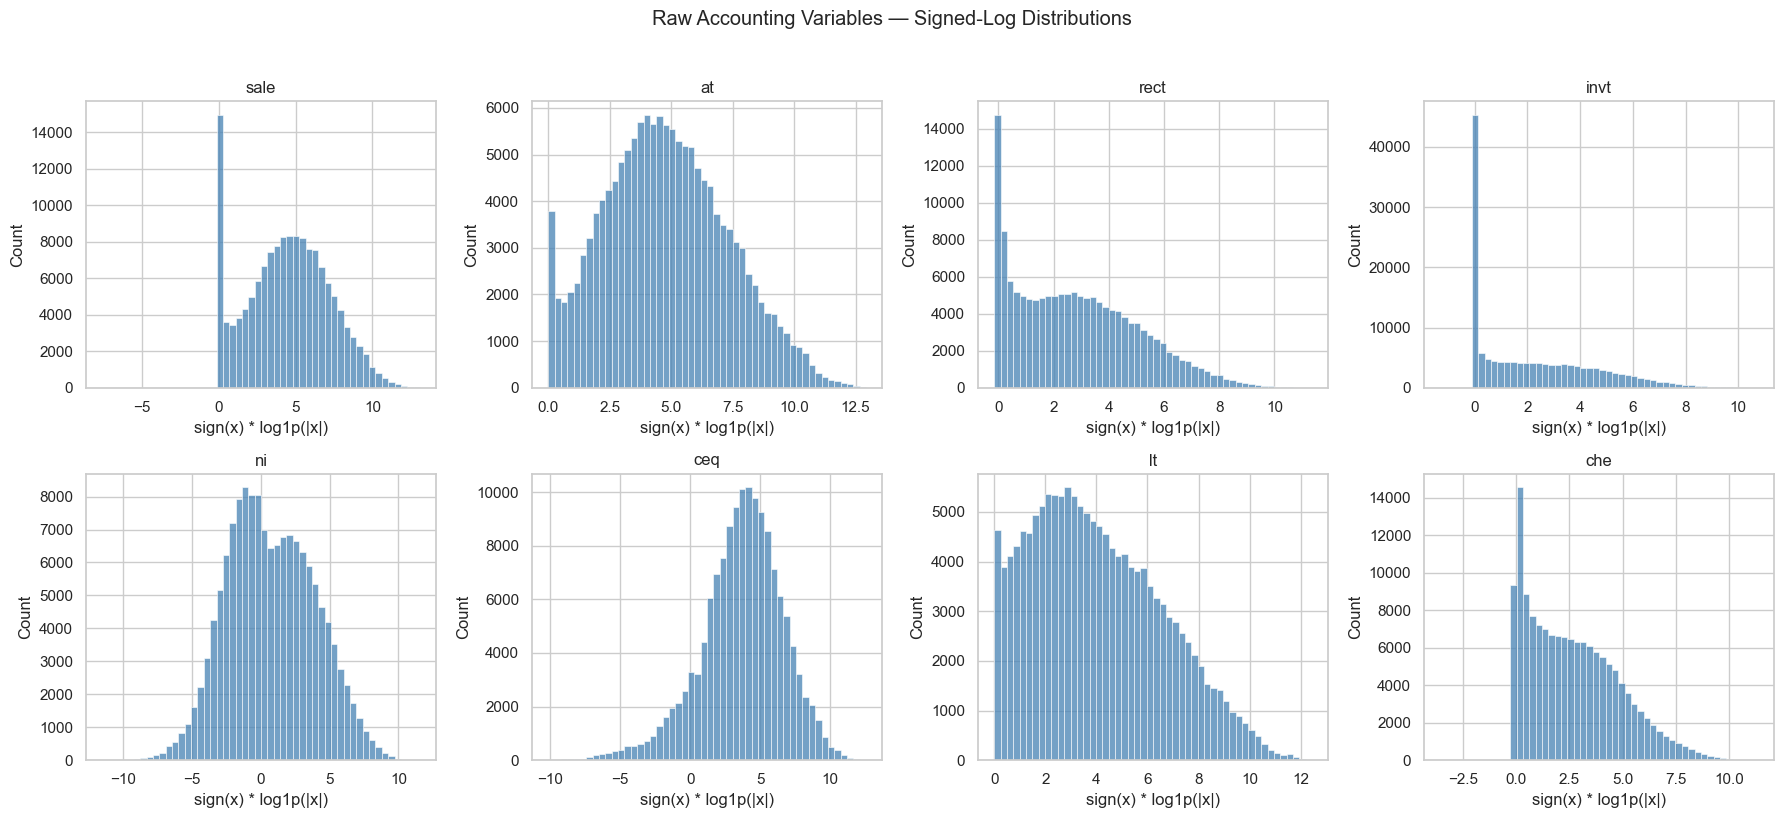

In [36]:
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

raw_focus = ["sale", "at", "rect", "invt", "ni", "ceq", "lt", "che"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, raw_focus):
    sns.histplot(signed_log(df[col].dropna()), bins=50, ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("sign(x) * log1p(|x|)")
    ax.set_ylabel("Count")
fig.suptitle("Raw Accounting Variables — Signed-Log Distributions", y=1.02)
plt.tight_layout()
plt.show()


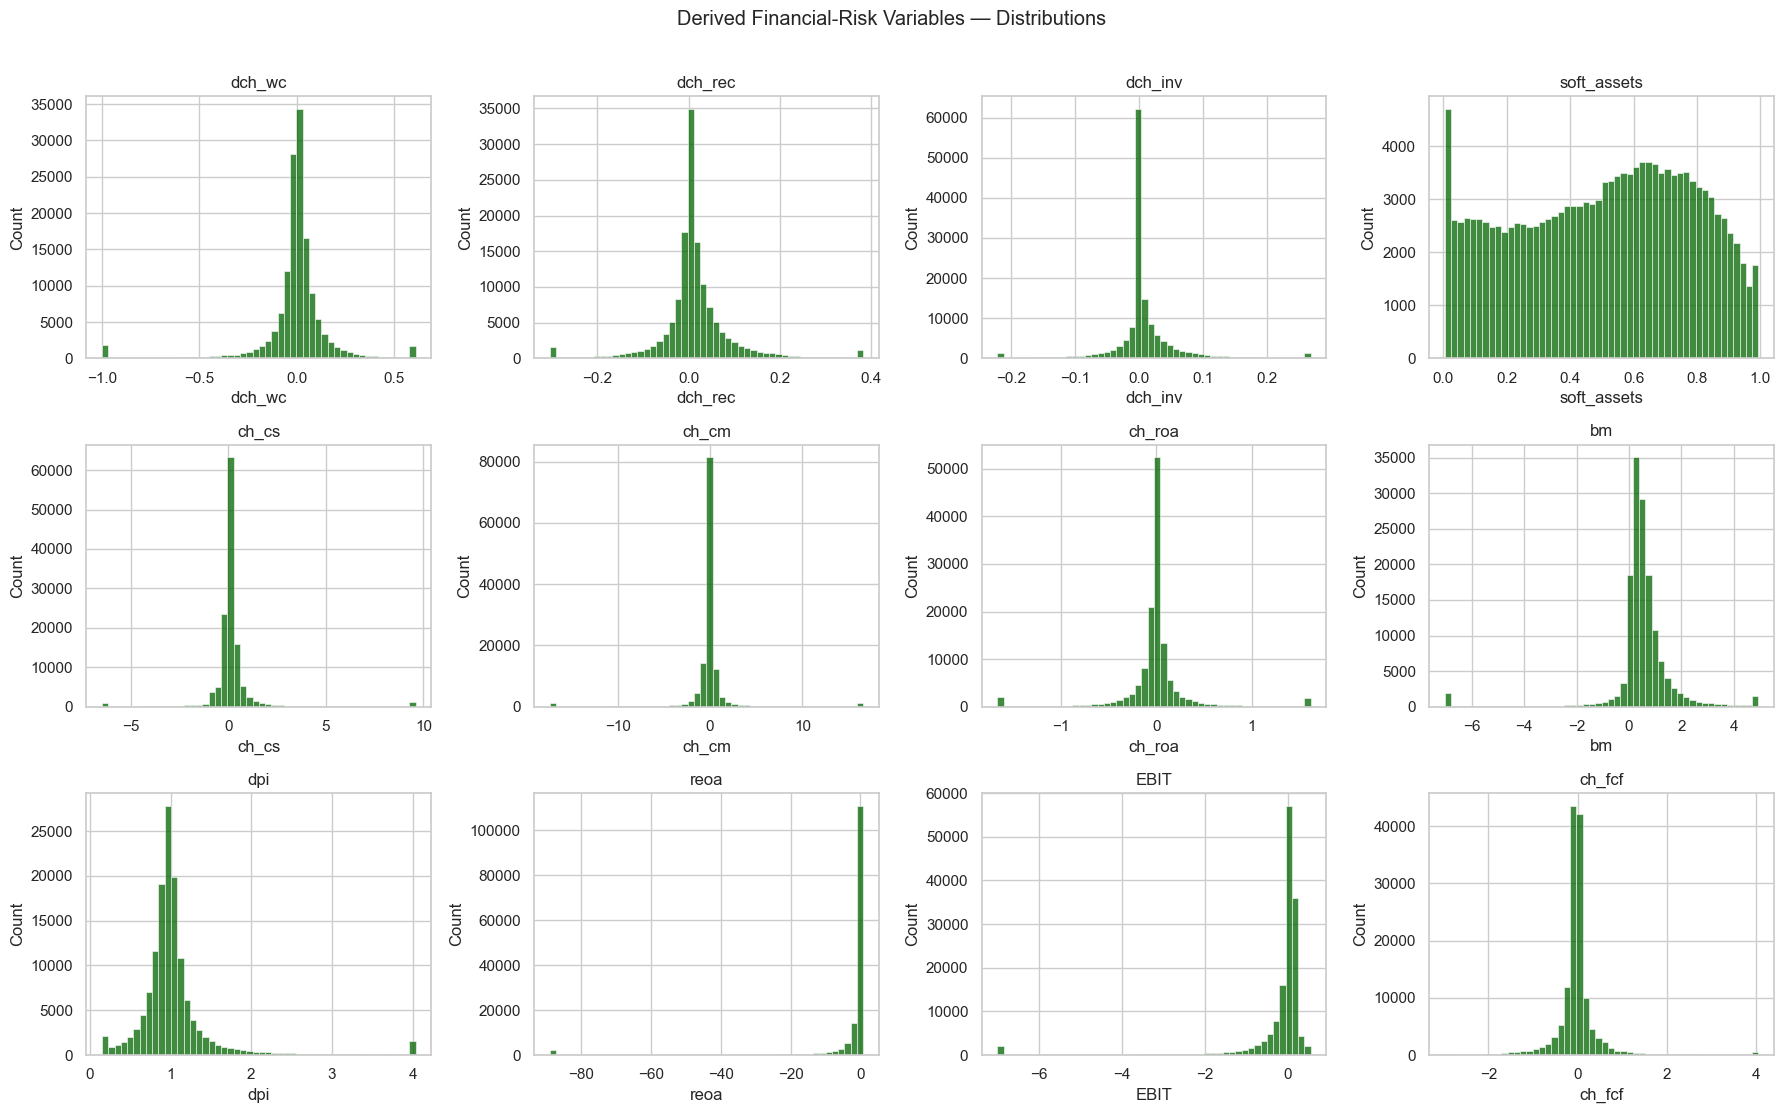

In [37]:
risk_focus = ["dch_wc", "dch_rec", "dch_inv", "soft_assets", "ch_cs", "ch_cm", "ch_roa",
              "bm", "dpi", "reoa", "EBIT", "ch_fcf"]

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.flat, risk_focus):
    sns.histplot(df[col].dropna(), bins=50, ax=ax, color="darkgreen")
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
fig.suptitle("Derived Financial-Risk Variables — Distributions", y=1.01)
plt.tight_layout()
plt.show()


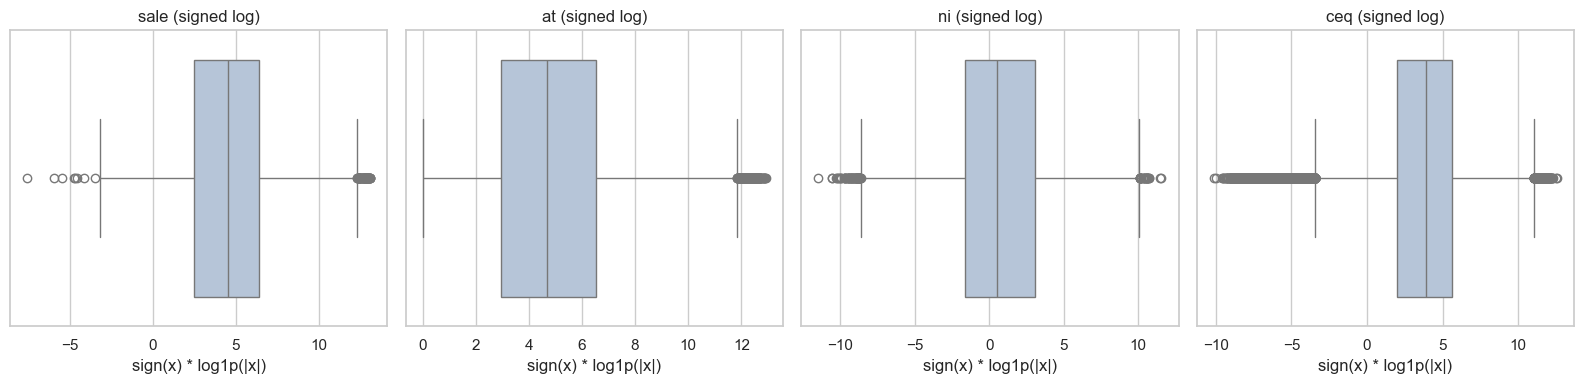

In [38]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["sale", "at", "ni", "ceq"]):
    sns.boxplot(x=signed_log(df[col].dropna()), ax=ax, color="lightsteelblue")
    ax.set_title(f"{col} (signed log)")
    ax.set_xlabel("sign(x) * log1p(|x|)")
plt.tight_layout()
plt.show()


In [39]:
class_counts = df[TARGET].value_counts()
class_pct = df[TARGET].value_counts(normalize=True) * 100

show(
    f"**Class counts:** {class_counts.to_dict()}  \n"
    f"**Class percentages:** {{0: {class_pct.get(0, 0):.4f}%, 1: {class_pct.get(1, 0):.4f}%}}"
)


**Class counts:** {0: 145081, 1: 964}  
**Class percentages:** {0: 99.3399%, 1: 0.6601%}

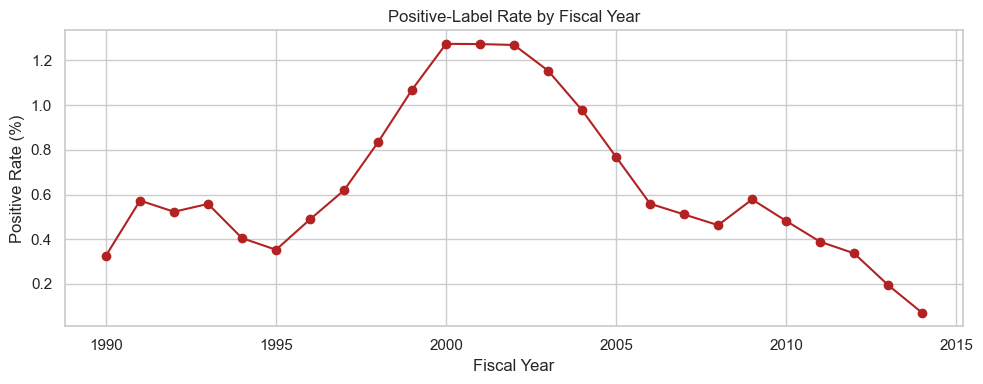

,n_obs,n_positive,positive_rate_pct
fyear,,,
1990,4582,15,0.327
1991,4713,27,0.573
1992,4970,26,0.523
1993,5377,30,0.558
1994,5684,23,0.405
1995,6230,22,0.353
1996,6745,33,0.489
1997,6789,42,0.619
1998,6716,56,0.834


In [40]:
year_group = df.groupby("fyear").agg(
    n_obs=("gvkey", "size"),
    n_positive=(TARGET, "sum"),
)
year_group["positive_rate_pct"] = (year_group["n_positive"] / year_group["n_obs"] * 100).round(3)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(year_group.index, year_group["positive_rate_pct"], marker="o", color="firebrick")
ax.set_title("Positive-Label Rate by Fiscal Year")
ax.set_xlabel("Fiscal Year")
ax.set_ylabel("Positive Rate (%)")
plt.tight_layout()
plt.show()

year_group


In [41]:
company_label_stats = df.groupby("gvkey")[TARGET].agg(["nunique", "sum", "count"])
company_label_stats.columns = ["n_distinct_labels", "n_positive_years", "n_total_years"]

n_companies_any_positive = int((company_label_stats["n_positive_years"] > 0).sum())
n_companies_mixed_labels = int((company_label_stats["n_distinct_labels"] > 1).sum())

show(
    f"**Companies with at least one positive label:** {n_companies_any_positive:,}  \n"
    f"**Companies with both positive and negative labels (repeated/mixed):** {n_companies_mixed_labels:,}"
)


**Companies with at least one positive label:** 402  
**Companies with both positive and negative labels (repeated/mixed):** 379

In [42]:
comparison_rows = []
for c in RATIO_VARS:
    grp0 = df.loc[df[TARGET] == 0, c].dropna()
    grp1 = df.loc[df[TARGET] == 1, c].dropna()
    comparison_rows.append({
        "variable": c,
        "median_misstate_0": grp0.median(),
        "median_misstate_1": grp1.median(),
        "mean_misstate_0": grp0.mean(),
        "mean_misstate_1": grp1.mean(),
        "iqr_misstate_0": grp0.quantile(0.75) - grp0.quantile(0.25),
        "iqr_misstate_1": grp1.quantile(0.75) - grp1.quantile(0.25),
    })
target_comparison = pd.DataFrame(comparison_rows).set_index("variable")
target_comparison


,median_misstate_0,median_misstate_1,mean_misstate_0,mean_misstate_1,iqr_misstate_0,iqr_misstate_1
variable,,,,,,
dch_wc,0.004,0.011,-0.005,0.024,0.077,0.083
ch_rsst,0.026,0.053,0.018,0.093,0.182,0.190
dch_rec,0.005,0.018,0.013,0.038,0.044,0.065
dch_inv,0.000,0.002,0.007,0.020,0.017,0.027
soft_assets,0.523,0.684,0.499,0.635,0.457,0.317
ch_cs,0.068,0.151,0.184,0.382,0.324,0.425
ch_cm,-0.023,-0.027,-0.091,-0.095,0.401,0.352
ch_roa,-0.002,-0.005,-0.010,-0.013,0.101,0.081
issue,1.000,1.000,0.863,0.963,0.000,0.000


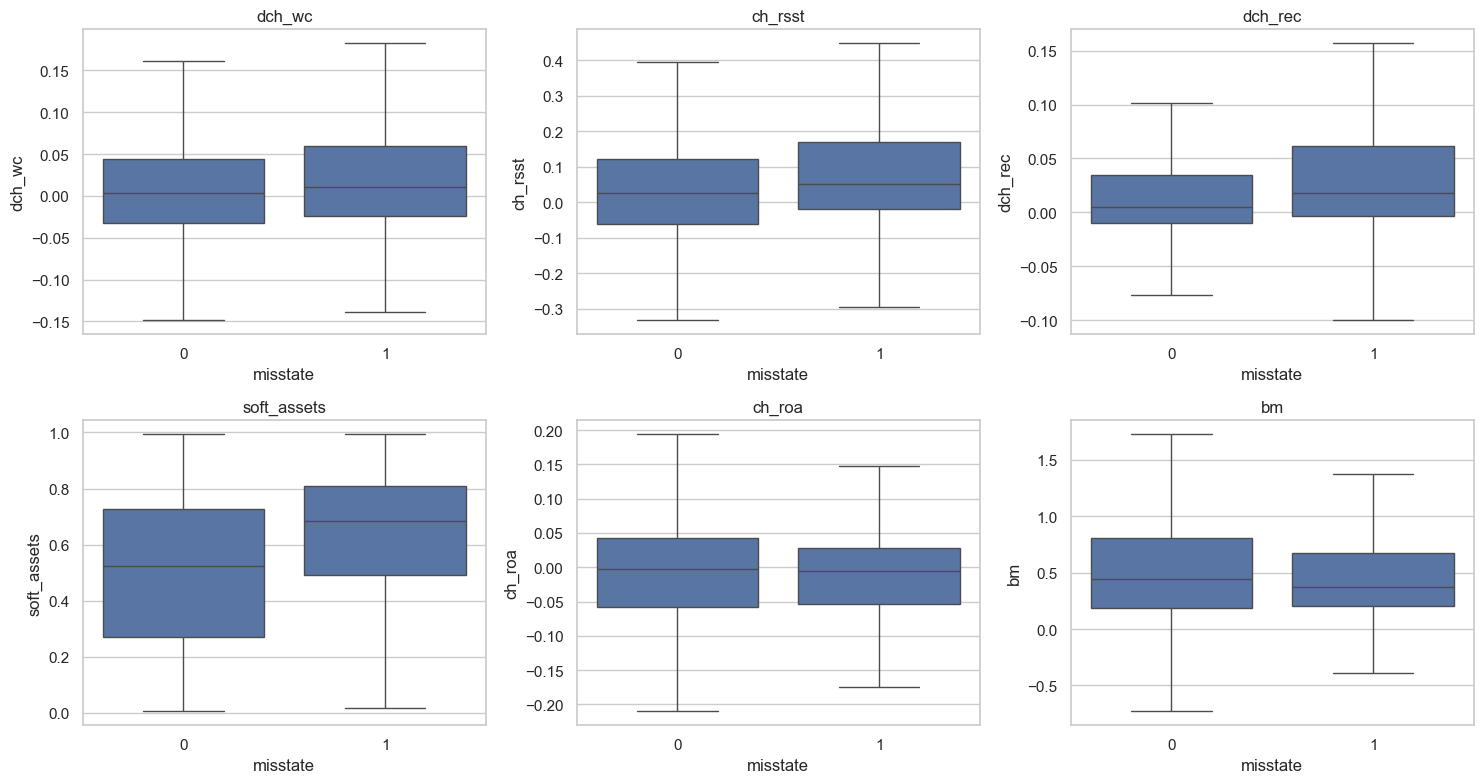

In [43]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
highlight = ["dch_wc", "ch_rsst", "dch_rec", "soft_assets", "ch_roa", "bm"]
for ax, col in zip(axes.flat, highlight):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax, showfliers=False)
    ax.set_xticklabels(["0", "1"])
    ax.set_title(col)
plt.tight_layout()
plt.show()


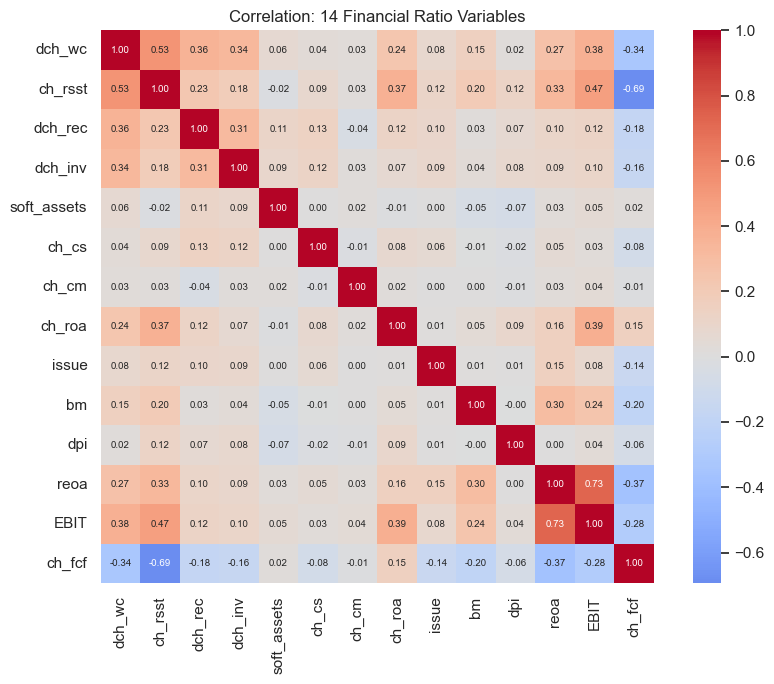

In [44]:
corr_matrix = df[RATIO_VARS].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, square=True,
            annot_kws={"size": 7})
ax.set_title("Correlation: 14 Financial Ratio Variables")
plt.tight_layout()
plt.show()


In [45]:
corr_unstacked = corr_matrix.where(~np.eye(len(corr_matrix), dtype=bool)).unstack().dropna()
corr_pairs = (
    corr_unstacked.reset_index()
    .rename(columns={"level_0": "variable_1", "level_1": "variable_2", 0: "correlation"})
)
corr_pairs["pair_key"] = corr_pairs.apply(lambda r: tuple(sorted([r["variable_1"], r["variable_2"]])), axis=1)
corr_pairs = corr_pairs.drop_duplicates(subset="pair_key").drop(columns="pair_key")
corr_pairs["abs_correlation"] = corr_pairs["correlation"].abs()

HIGH_CORR_THRESHOLD = 0.6
high_corr_pairs = corr_pairs[corr_pairs["abs_correlation"] >= HIGH_CORR_THRESHOLD].sort_values(
    "abs_correlation", ascending=False
)
show(f"**Pairs with |correlation| >= {HIGH_CORR_THRESHOLD}:** {len(high_corr_pairs)}")
high_corr_pairs.drop(columns="abs_correlation") if len(high_corr_pairs) else pd.DataFrame({"note": ["No pairs met the threshold."]})


**Pairs with |correlation| >= 0.6:** 2

,variable_1,variable_2,correlation
154,reoa,EBIT,0.732
25,ch_rsst,ch_fcf,-0.694


In [46]:
feature_classification = pd.DataFrame([
    ("misstate", "A. Target", "The label to be classified."),
    ("gvkey", "B. Identifier/grouping", "Company identifier — used for grouping in cross-validation and traceability, not as a predictive input."),
    ("p_aaer", "C. Label-related metadata / leakage", "Non-null iff misstate==1 (verified in Phase 1 and re-checked below) — a direct proxy for the target."),
    ("fyear", "D. Time/context", "Real temporal information; the target's base rate drifts across fiscal years (Phase 1, Section 21)."),
] + [(c, "E. Candidate predictive feature (raw accounting)", "Contemporaneous financial-statement variable.") for c in RAW_VARS]
  + [(c, "E. Candidate predictive feature (derived ratio)", "Contemporaneous, derived financial-risk variable.") for c in RATIO_VARS],
    columns=["variable", "classification", "note"]
)
feature_classification


,variable,classification,note
0,misstate,A. Target,The label to be classified.
1,gvkey,B. Identifier/grouping,Company identifier — used for grouping in cros...
2,p_aaer,C. Label-related metadata / leakage,Non-null iff misstate==1 (verified in Phase 1 ...
3,fyear,D. Time/context,Real temporal information; the target's base r...
4,act,E. Candidate predictive feature (raw accounting),Contemporaneous financial-statement variable.
5,ap,E. Candidate predictive feature (raw accounting),Contemporaneous financial-statement variable.
6,at,E. Candidate predictive feature (raw accounting),Contemporaneous financial-statement variable.
7,ceq,E. Candidate predictive feature (raw accounting),Contemporaneous financial-statement variable.
8,che,E. Candidate predictive feature (raw accounting),Contemporaneous financial-statement variable.
9,cogs,E. Candidate predictive feature (raw accounting),Contemporaneous financial-statement variable.


In [47]:
# Re-verify p_aaer's relationship to misstate directly in this notebook (not assumed from Phase 1).
n_paaer_notna_misstate_0 = int(((df["p_aaer"].notna()) & (df[TARGET] == 0)).sum())
n_paaer_na_misstate_1 = int(((df["p_aaer"].isna()) & (df[TARGET] == 1)).sum())
paaer_is_label_proxy = (n_paaer_notna_misstate_0 == 0) and (n_paaer_na_misstate_1 == 0)

show(
    f"**p_aaer non-null AND misstate==0:** {n_paaer_notna_misstate_0}  \n"
    f"**p_aaer null AND misstate==1:** {n_paaer_na_misstate_1}  \n"
    f"**Confirmed p_aaer is a direct label proxy:** {paaer_is_label_proxy}"
)


**p_aaer non-null AND misstate==0:** 0  
**p_aaer null AND misstate==1:** 0  
**Confirmed p_aaer is a direct label proxy:** True

In [48]:
feature_selection_table = pd.DataFrame([
    ("p_aaer", "EXCLUDE from candidate predictors; RETAIN in df_clean", "Direct label proxy — non-null iff misstate==1 (verified in Section 11)."),
    ("gvkey", "EXCLUDE from candidate predictors; RETAIN in df_clean", "Company identifier — retained only for grouping/validation, not predictive content."),
    ("fyear", "EXCLUDE as an ordinary numeric predictor for now; RETAIN in df_clean", "Carries target base-rate drift (Section 9); needed for temporal validation design; final treatment deferred to Phase 3 (Section 11)."),
    ("28 raw accounting variables", "RETAIN as candidate predictors", "Contemporaneous financial-statement data; no missing values (Phase 1)."),
    ("13 derived ratio variables (excl. issue)", "RETAIN as candidate predictors", "Contemporaneous, scaled financial-risk variables; missingness documented and intentionally not imputed here (Section 4)."),
    ("issue", "RETAIN as candidate predictor", "Binary, empirically-verified financing-activity flag (Phase 1); no missingness."),
], columns=["feature_group", "treatment", "reason"])
feature_selection_table


,feature_group,treatment,reason
0,p_aaer,EXCLUDE from candidate predictors; RETAIN in d...,Direct label proxy — non-null iff misstate==1 ...
1,gvkey,EXCLUDE from candidate predictors; RETAIN in d...,Company identifier — retained only for groupin...
2,fyear,EXCLUDE as an ordinary numeric predictor for n...,Carries target base-rate drift (Section 9); ne...
3,28 raw accounting variables,RETAIN as candidate predictors,Contemporaneous financial-statement data; no m...
4,13 derived ratio variables (excl. issue),RETAIN as candidate predictors,"Contemporaneous, scaled financial-risk variabl..."
5,issue,RETAIN as candidate predictor,"Binary, empirically-verified financing-activit..."


In [49]:
df_clean = df.copy()

# EXPLORATORY FULL-DATASET WINSORIZED VIEWS ONLY.
# These _winsorized columns use thresholds computed on the ENTIRE dataset (Section 7)
# and are added purely for diagnostic/visual comparison in this notebook. They are
# NOT leakage-safe modeling features: Phase 3 must recompute winsorization thresholds
# using training data only and apply them to validation/test data separately.
for c in WINSORIZE_VARS:
    lb, ub = winsor_thresholds[c]
    df_clean[f"{c}_winsorized_EXPLORATORY_FULLDATA"] = df_clean[c].clip(lower=lb, upper=ub)

show(
    f"**df_clean shape:** {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns  \n"
    f"(original {df.shape[1]} columns + {len(WINSORIZE_VARS)} added exploratory "
    f"`_winsorized_EXPLORATORY_FULLDATA` variants — full-dataset thresholds, diagnostic use only)"
)


**df_clean shape:** 146,045 rows x 59 columns  
(original 46 columns + 13 added exploratory `_winsorized_EXPLORATORY_FULLDATA` variants — full-dataset thresholds, diagnostic use only)

In [50]:
# Verify the original unsuffixed financial variables in df_clean are byte-identical
# to df for the corresponding columns — i.e. the exploratory winsorized columns are
# purely additive and did not alter any original column.
unsuffixed_cols = [c for c in df.columns]
unchanged = all(df_clean[c].equals(df[c]) for c in unsuffixed_cols)
assert unchanged, "An original column was altered when constructing df_clean — investigate."

show(f"**Original unsuffixed columns unchanged in df_clean (identical to df):** {unchanged}")

**Original unsuffixed columns unchanged in df_clean (identical to df):** True

In [51]:
after_snapshot = dataset_snapshot(df_clean, "AFTER cleaning (df_clean)")
snapshot_log.append(after_snapshot)

final_comparison = pd.DataFrame(snapshot_log)
final_comparison


,snapshot,rows,columns,unique_companies,year_min,year_max,positive_labels,positive_pct,missing_cells,duplicate_rows,duplicate_gvkey_fyear
0,BEFORE cleaning,146045,46,18444,1990,2014,964,0.660,226179,0,0
1,AFTER cleaning (df_clean),146045,59,18444,1990,2014,964,0.660,307277,0,0


In [52]:
validation_results = []

def check(name, condition):
    validation_results.append({"check": name, "passed": bool(condition)})

check("No duplicate (gvkey, fyear) pairs in df_clean",
      df_clean.duplicated(subset=["gvkey", "fyear"]).sum() == 0)
check("Target contains only {0, 1}",
      set(df_clean[TARGET].unique()).issubset({0, 1}))
check("No infinite values remain in raw/ratio variables",
      sum(int(np.isinf(df_clean[c].astype(float)).sum()) for c in RAW_VARS + RATIO_VARS) == 0)
check("gvkey has no missing values",
      df_clean["gvkey"].isna().sum() == 0)
check("fyear has no missing values",
      df_clean["fyear"].isna().sum() == 0)
check("df_raw is unchanged (row count matches original load)",
      len(df_raw) == baseline_snapshot["rows"] and df_raw.shape[1] == 46)
check("df_clean row count matches df (no rows added/removed during cleaning)",
      len(df_clean) == len(df))
check("df_clean positive-label count matches pre-cleaning baseline",
      int(df_clean[TARGET].sum()) == baseline_snapshot["positive_labels"])

validation_table = pd.DataFrame(validation_results)
all_passed = validation_table["passed"].all()
validation_table


,check,passed
0,"No duplicate (gvkey, fyear) pairs in df_clean",True
1,"Target contains only {0, 1}",True
2,No infinite values remain in raw/ratio variables,True
3,gvkey has no missing values,True
4,fyear has no missing values,True
5,df_raw is unchanged (row count matches origina...,True
6,df_clean row count matches df (no rows added/r...,True
7,df_clean positive-label count matches pre-clea...,True


In [53]:
for row in validation_results:
    assert row["passed"], f"Validation check failed: {row['check']}"

show(f"**All {len(validation_results)} validation checks passed:** {all_passed}")


**All 8 validation checks passed:** True

In [54]:
def median_gap(col):
    g0 = df.loc[df[TARGET] == 0, col].dropna().median()
    g1 = df.loc[df[TARGET] == 1, col].dropna().median()
    return g0, g1

wc_g0, wc_g1 = median_gap("dch_wc")
rec_g0, rec_g1 = median_gap("dch_rec")
inv_g0, inv_g1 = median_gap("dch_inv")
soft_g0, soft_g1 = median_gap("soft_assets")
roa_g0, roa_g1 = median_gap("ch_roa")
fcf_g0, fcf_g1 = median_gap("ch_fcf")
bm_g0, bm_g1 = median_gap("bm")
issue_rate_0 = df.loc[df[TARGET] == 0, "issue"].mean() * 100
issue_rate_1 = df.loc[df[TARGET] == 1, "issue"].mean() * 100

findings_text = f'''
### Finding: Working-capital accrual changes differ by label group
**Evidence:** median `dch_wc` is {wc_g0:.4f} for misstate=0 vs. {wc_g1:.4f} for misstate=1 (Section 9).
**Risk/Analytical Implication:** consistent with accrual-based earnings-management theory in the literature; a candidate predictive feature, not evidence of manipulation in any individual case.

### Finding: Receivables and inventory change patterns differ by label group
**Evidence:** median `dch_rec` is {rec_g0:.4f} vs. {rec_g1:.4f}; median `dch_inv` is {inv_g0:.4f} vs. {inv_g1:.4f} (Section 9).
**Risk/Analytical Implication:** a potential risk-related signal tied to revenue-recognition/inventory-timing theories in the literature; historical association only.

### Finding: Soft-asset proportion differs by label group
**Evidence:** median `soft_assets` is {soft_g0:.4f} vs. {soft_g1:.4f} (Section 9).
**Risk/Analytical Implication:** consistent with asset-quality risk theory; a candidate feature for Phase 3, not a standalone conclusion.

### Finding: Profitability-change and cash-flow-change variables differ by label group
**Evidence:** median `ch_roa` is {roa_g0:.4f} vs. {roa_g1:.4f}; median `ch_fcf` is {fcf_g0:.4f} vs. {fcf_g1:.4f} (Section 9).
**Risk/Analytical Implication:** consistent with performance-pressure and earnings/cash-divergence theories; historical association, not causal evidence.

### Finding: Valuation (book-to-market) differs by label group
**Evidence:** median `bm` is {bm_g0:.4f} vs. {bm_g1:.4f} (Section 9).
**Risk/Analytical Implication:** consistent with growth/valuation-pressure theory; a candidate feature, not a standalone risk determination.

### Finding: Financing/issuance activity rate differs by label group
**Evidence:** `issue` flag rate is {issue_rate_0:.2f}% for misstate=0 vs. {issue_rate_1:.2f}% for misstate=1 (Section 9 data).
**Risk/Analytical Implication:** consistent with financing-pressure theory (firms raising capital may face heightened scrutiny or incentive pressure); historical association only.
'''
show(findings_text)



### Finding: Working-capital accrual changes differ by label group
**Evidence:** median `dch_wc` is 0.0035 for misstate=0 vs. 0.0106 for misstate=1 (Section 9).
**Risk/Analytical Implication:** consistent with accrual-based earnings-management theory in the literature; a candidate predictive feature, not evidence of manipulation in any individual case.

### Finding: Receivables and inventory change patterns differ by label group
**Evidence:** median `dch_rec` is 0.0049 vs. 0.0183; median `dch_inv` is 0.0000 vs. 0.0018 (Section 9).
**Risk/Analytical Implication:** a potential risk-related signal tied to revenue-recognition/inventory-timing theories in the literature; historical association only.

### Finding: Soft-asset proportion differs by label group
**Evidence:** median `soft_assets` is 0.5234 vs. 0.6839 (Section 9).
**Risk/Analytical Implication:** consistent with asset-quality risk theory; a candidate feature for Phase 3, not a standalone conclusion.

### Finding: Profitability-change and cash-flow-change variables differ by label group
**Evidence:** median `ch_roa` is -0.0019 vs. -0.0048; median `ch_fcf` is -0.0260 vs. -0.0505 (Section 9).
**Risk/Analytical Implication:** consistent with performance-pressure and earnings/cash-divergence theories; historical association, not causal evidence.

### Finding: Valuation (book-to-market) differs by label group
**Evidence:** median `bm` is 0.4426 vs. 0.3771 (Section 9).
**Risk/Analytical Implication:** consistent with growth/valuation-pressure theory; a candidate feature, not a standalone risk determination.

### Finding: Financing/issuance activity rate differs by label group
**Evidence:** `issue` flag rate is 86.28% for misstate=0 vs. 96.27% for misstate=1 (Section 9 data).
**Risk/Analytical Implication:** consistent with financing-pressure theory (firms raising capital may face heightened scrutiny or incentive pressure); historical association only.


In [55]:
decision_log = pd.DataFrame([
    (
        "Missing values in 13 derived ratio variables",
        f"{len(ratio_missing_vars)} ratio variables affected, {missing_target_table['missing_pct'].max():.2f}% missing at most (Section 4)",
        "Retain as NaN in df_clean; do not impute in this notebook",
        "Missingness reflects an undefined ratio (e.g. no prior-year baseline), not a true zero; imputation belongs in a train-only Phase 3 pipeline to avoid leakage",
        "No rows dropped; no fabricated values introduced; Phase 3 must handle NaNs explicitly (native support or train-fit imputation)",
    ),
    (
        "Implausible negative values in act, che, invt, rect, sale",
        f"Counts: {dict(zip(classification_table['variable'], classification_table['negative_count'])) if len(classification_table) else 'see Section 5'}",
        "Retain values; document as an unresolved data-quality limitation",
        "No independent way to confirm error vs. genuine unusual transaction vs. source-data artifact from this data alone",
        "A small number of rows carry unverified negative values in these columns; flagged for any future access to source documentation",
    ),
    (
        "Infinite values in raw/ratio variables",
        f"{total_inf_before} infinite values found before treatment (Section 6)",
        "Convert +/-inf to NaN, fold into missing-value handling",
        "An infinite ratio does not invalidate the rest of that company-year's data; dropping the row would lose 40+ other valid variables",
        "Any inf-affected cells now follow the Section 4 missing-value decision instead of remaining unusable",
    ),
    (
        "Extreme values (IQR outliers) in ratio variables",
        "Outlier rates per variable computed in Section 7",
        "No deletion. Exploratory 1%/99% winsorized views are retained for diagnostic comparison. Final modeling-time winsorization, if selected, must be fitted on training data only in Phase 3.",
        "Full-dataset percentile thresholds are useful for understanding the effect of extreme values, but reusing them directly for modeling would leak validation/test information into a transformation applied to training rows",
        "df_clean contains the original, untouched ratio variables plus exploratory-only _winsorized_EXPLORATORY_FULLDATA columns; these exploratory columns are NOT considered leakage-safe modeling features",
    ),
    (
        "p_aaer as a candidate feature",
        "Verified non-null iff misstate==1 (Section 11)",
        "Exclude from candidate predictors; retain in df_clean for traceability",
        "Direct label proxy — including it would leak the target",
        "Removed from any future X matrix; available for identification/audit trail",
    ),
    (
        "gvkey as a candidate feature",
        "18,444 unique companies; some with many repeated years (Phase 1)",
        "Exclude from candidate predictors; retain in df_clean for grouping",
        "Using it directly risks the model memorizing specific companies rather than learning generalizable financial-risk patterns",
        "Available for group-aware train/test splitting in Phase 3",
    ),
    (
        "fyear treatment",
        "Positive-label rate drifts across fiscal years (Section 9)",
        "Retain in df_clean; do not treat as an ordinary numeric predictor here; final treatment deferred",
        "Carries target base-rate information that could be exploited rather than genuine risk signal, but is also needed for time-aware validation design",
        "Explicit open decision carried into Phase 3, not resolved arbitrarily",
    ),
], columns=["issue", "evidence", "decision", "rationale", "impact"])
decision_log


,issue,evidence,decision,rationale,impact
0,Missing values in 13 derived ratio variables,"13 ratio variables affected, 11.71% missing at...",Retain as NaN in df_clean; do not impute in th...,Missingness reflects an undefined ratio (e.g. ...,No rows dropped; no fabricated values introduc...
1,"Implausible negative values in act, che, invt,...","Counts: {'act': 8, 'ceq': 15863, 'che': 31, 'c...",Retain values; document as an unresolved data-...,No independent way to confirm error vs. genuin...,A small number of rows carry unverified negati...
2,Infinite values in raw/ratio variables,0 infinite values found before treatment (Sect...,"Convert +/-inf to NaN, fold into missing-value...",An infinite ratio does not invalidate the rest...,Any inf-affected cells now follow the Section ...
3,Extreme values (IQR outliers) in ratio variables,Outlier rates per variable computed in Section 7,No deletion. Exploratory 1%/99% winsorized vie...,Full-dataset percentile thresholds are useful ...,"df_clean contains the original, untouched rati..."
4,p_aaer as a candidate feature,Verified non-null iff misstate==1 (Section 11),Exclude from candidate predictors; retain in d...,Direct label proxy — including it would leak t...,Removed from any future X matrix; available fo...
5,gvkey as a candidate feature,"18,444 unique companies; some with many repeat...",Exclude from candidate predictors; retain in d...,Using it directly risks the model memorizing s...,Available for group-aware train/test splitting...
6,fyear treatment,Positive-label rate drifts across fiscal years...,Retain in df_clean; do not treat as an ordinar...,Carries target base-rate information that coul...,"Explicit open decision carried into Phase 3, n..."


In [56]:
summary_text = f'''
### What changed
- {inf_replaced_counts if inf_replaced_counts else "No"} infinite-value conversions applied (Section 6).
- {len(WINSORIZE_VARS)} exploratory `_winsorized_EXPLORATORY_FULLDATA` columns were generated using full-dataset 1st/99th percentile thresholds for diagnostic analysis only (Section 7, 13). These columns are NOT considered leakage-safe modeling features. If winsorization is used in Phase 3, thresholds must be learned from training data only.

### What was retained
- All {len(df_clean):,} rows and all {df.shape[1]} original columns — no rows removed, no positive-label observations removed, no columns deleted (Sections 13, 14).
- Missing values in the derived ratio variables, left as NaN rather than imputed (Section 4).
- Implausible negative values, documented rather than corrected (Section 5).
- `gvkey`, `fyear`, and `p_aaer`, retained in df_clean for grouping, temporal analysis, and traceability respectively — excluded only from the candidate predictive-feature set (Sections 11, 12).

### What was excluded (from candidate predictive features only, not from df_clean)
- `p_aaer` — direct label proxy (Section 11).
- `gvkey` — identifier, not a financial characteristic (Section 11).
- `fyear` as an ordinary numeric predictor — final treatment deferred to Phase 3 (Section 11).

### Remaining limitations
- The cause of the implausible negative values in act/che/invt/rect/sale remains unverified (Section 5).
- Whether ratio-variable missingness is related to first-year-in-panel status (hypothesized in Phase 1) was not directly tested in this notebook.
- The choice between raw and ratio feature variants is not finalized. The exploratory winsorized columns are diagnostic-only and must NOT be used as-is for modeling.
- Severe class imbalance (positive rate {df[TARGET].mean() * 100:.4f}%) means all group-level comparisons in this notebook remain descriptive, not statistically confirmatory.

### Modeling preparation status
- A documented, reproducible `df_clean` dataset now exists with {df_clean.shape[1]} columns and {len(df_clean):,} rows.
- A candidate feature-treatment table (Section 12) and a full decision log (Section 16) are available to justify every choice a reviewer might question.
- {int(validation_table["passed"].sum())} of {len(validation_table)} automated data-quality validation checks passed (Section 14).

**Phase 2 prepares the analytical dataset but does not train or evaluate a machine-learning model.**

### Next phase
Phase 3 — Modeling & Validation Design: finalize the feature set (raw vs. ratio
variants, and the fyear decision left open in Section 11), design a group-aware and/or
time-aware train/test split consistent with Phase 1's findings, and only then proceed
to model training and evaluation.

**Phase 3 winsorization note:** Phase 3 must implement any winsorization inside the
validation/training workflow so transformation parameters are learned exclusively from
the training portion of each split/fold — never from the full dataset, and never from
validation/test rows.
'''
show(summary_text)



### What changed
- No infinite-value conversions applied (Section 6).
- 13 exploratory `_winsorized_EXPLORATORY_FULLDATA` columns were generated using full-dataset 1st/99th percentile thresholds for diagnostic analysis only (Section 7, 13). These columns are NOT considered leakage-safe modeling features. If winsorization is used in Phase 3, thresholds must be learned from training data only.

### What was retained
- All 146,045 rows and all 46 original columns — no rows removed, no positive-label observations removed, no columns deleted (Sections 13, 14).
- Missing values in the derived ratio variables, left as NaN rather than imputed (Section 4).
- Implausible negative values, documented rather than corrected (Section 5).
- `gvkey`, `fyear`, and `p_aaer`, retained in df_clean for grouping, temporal analysis, and traceability respectively — excluded only from the candidate predictive-feature set (Sections 11, 12).

### What was excluded (from candidate predictive features only, not from df_clean)
- `p_aaer` — direct label proxy (Section 11).
- `gvkey` — identifier, not a financial characteristic (Section 11).
- `fyear` as an ordinary numeric predictor — final treatment deferred to Phase 3 (Section 11).

### Remaining limitations
- The cause of the implausible negative values in act/che/invt/rect/sale remains unverified (Section 5).
- Whether ratio-variable missingness is related to first-year-in-panel status (hypothesized in Phase 1) was not directly tested in this notebook.
- The choice between raw and ratio feature variants is not finalized. The exploratory winsorized columns are diagnostic-only and must NOT be used as-is for modeling.
- Severe class imbalance (positive rate 0.6601%) means all group-level comparisons in this notebook remain descriptive, not statistically confirmatory.

### Modeling preparation status
- A documented, reproducible `df_clean` dataset now exists with 59 columns and 146,045 rows.
- A candidate feature-treatment table (Section 12) and a full decision log (Section 16) are available to justify every choice a reviewer might question.
- 8 of 8 automated data-quality validation checks passed (Section 14).

**Phase 2 prepares the analytical dataset but does not train or evaluate a machine-learning model.**

### Next phase
Phase 3 — Modeling & Validation Design: finalize the feature set (raw vs. ratio
variants, and the fyear decision left open in Section 11), design a group-aware and/or
time-aware train/test split consistent with Phase 1's findings, and only then proceed
to model training and evaluation.

**Phase 3 winsorization note:** Phase 3 must implement any winsorization inside the
validation/training workflow so transformation parameters are learned exclusively from
the training portion of each split/fold — never from the full dataset, and never from
validation/test rows.
